# Next Book Prediction on Goodreads
**CSE 158 Assignment 2** · Team: Woosik, Shriya, Chase, Aung

**Predictive task:** given the ordered sequence of books a user has interacted with, predict which book they will interact with next.

| Section | Owner | Status |
|---|---|---|
| 0. Shared data pipeline and evaluation helpers | Woosik | done (do not edit without telling the team) |
| 1. Predictive task, evaluation plan, baselines | Shriya | TODO |
| 2. Exploratory analysis and preprocessing | Chase | starter cells |
| 3. Modeling | Woosik | baselines done, more models TODO |
| 4. Evaluation | Aung | starter cells |
| 5. Related work | Shriya | TODO |

Run the notebook top to bottom. Every section uses the same split (`train_df`, `valid_df`, `test_df`) and the same evaluation functions from Section 0, so all numbers are comparable.

## 0. Shared data pipeline (Woosik)

**Data:** `task_5_train.csv` from Assignment 1 (Goodreads interactions, anonymized user and item IDs). Each row is one user interacting with one book: `user, item, timestamp, rating` (rating 0 means "shelved but not rated").

**Split (leave last out):** for every user, sort interactions by time.
* last interaction → **test**
* second to last → **validation** (use this for tuning)
* everything earlier → **train**

**Why this split:** it matches the real use case (predict what comes next from the past only) and it is the standard protocol in sequential recommendation papers (e.g. SASRec).

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import time, warnings
warnings.filterwarnings("ignore")

DATA_PATH = "task_5_train.csv"   # change if the file is elsewhere
SEED = 0
rng = np.random.RandomState(SEED)

In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.sort_values(["user", "timestamp"], kind="stable").reset_index(drop=True)
print(f"{len(df):,} interactions | {df.user.nunique():,} users | {df['item'].nunique():,} items")
print("interactions per user (min/median/max):", df.groupby('user').size().agg(['min', 'median', 'max']).tolist())
df.head()

2,554,047 interactions | 86,786 users | 232,427 items


interactions per user (min/median/max): [4.0, 12.0, 2843.0]


,user,item,timestamp,rating
0,u0000227953,i3318023479,1318061891,4
1,u0000227953,i1066938559,1321168991,4
2,u0000227953,i8628800151,1324190915,4
3,u0000227953,i7702466278,1325834624,5
4,u0000227953,i7247640406,1327477632,4


In [3]:
# leave-last-out split
pos_from_end = df.groupby("user").cumcount(ascending=False)
test_df  = df[pos_from_end == 0].reset_index(drop=True)
valid_df = df[pos_from_end == 1].reset_index(drop=True)
train_df = df[pos_from_end >= 2].reset_index(drop=True)
print(f"train {len(train_df):,} | valid {len(valid_df):,} | test {len(test_df):,}")

train 2,380,475 | valid 86,786 | test 86,786


### Evaluation helpers (shared by every model)

A model is any object with a method `score(users, items) -> np.array` that returns one number per (user, item) pair; higher means "more likely next".

Two protocols:
1. **Pairwise accuracy** (same as Assignment 1 Task 5): the true next item vs. one negative item. Chance = 0.5.
2. **Sampled ranking:** the true next item is ranked among itself plus 99 negatives. We report **HR@10** (is the true item in the top 10?), **NDCG@10** (like HR@10 but rewards ranking it higher) and **MRR** (average of 1 / rank).

**Negatives** are drawn in proportion to item popularity (a random training interaction's item), excluding books the user already has. This mirrors how the Assignment 1 test set was built and makes the task harder than uniform negatives, because popular items cannot win just by being popular.

`history` passed to models always comes from `train_df` (for validation) or `train_df + valid_df` (for test), never from the target itself.

In [4]:
N_NEG = 99
N_EVAL_USERS = 20000   # ranking metrics on a fixed random subset of users to keep runtime low

def sample_negatives(target_df, history_df, n_neg, seed):
    """n_neg popularity-weighted negatives per row, excluding the user's own items and the target."""
    r = np.random.RandomState(seed)
    pool = history_df["item"].values
    seen = history_df.groupby("user")["item"].apply(set).to_dict()
    out = np.empty((len(target_df), n_neg), dtype=object)
    for n, (u, pos) in enumerate(zip(target_df.user.values, target_df["item"].values)):
        bad = seen.get(u, set()) | {pos}
        negs = []
        while len(negs) < n_neg:
            cand = pool[r.randint(0, len(pool), n_neg * 2)]
            negs.extend(c for c in cand if c not in bad)
        out[n] = negs[:n_neg]
    return out

eval_users = rng.choice(df.user.unique(), size=min(N_EVAL_USERS, df.user.nunique()), replace=False)
eval_mask_valid = valid_df.user.isin(eval_users).values
eval_mask_test = test_df.user.isin(eval_users).values

t = time.time()
NEG = {
    "valid": sample_negatives(valid_df[eval_mask_valid], train_df, N_NEG, seed=1),
    "test":  sample_negatives(test_df[eval_mask_test], pd.concat([train_df, valid_df]), N_NEG, seed=2),
}
PAIR_NEG = {   # one negative per user for pairwise accuracy (all users)
    "valid": sample_negatives(valid_df, train_df, 1, seed=3)[:, 0],
    "test":  sample_negatives(test_df, pd.concat([train_df, valid_df]), 1, seed=4)[:, 0],
}
print(f"negatives sampled in {time.time() - t:.0f}s")

negatives sampled in 18s


In [5]:
def evaluate(model, split="valid", k=10):
    """Returns pairwise accuracy (all users) and HR@k / NDCG@k / MRR (eval subset) for one split."""
    target = valid_df if split == "valid" else test_df
    users, pos = target.user.values, target["item"].values
    s_pos = model.score(users, pos)
    s_neg = model.score(users, PAIR_NEG[split])
    pair_acc = np.mean(s_pos > s_neg) + 0.5 * np.mean(s_pos == s_neg)

    mask = eval_mask_valid if split == "valid" else eval_mask_test
    tu, tp, negs = users[mask], pos[mask], NEG[split]
    cand = np.c_[tp, negs]                                   # column 0 is the true item
    S = model.score(np.repeat(tu, cand.shape[1]), cand.ravel()).reshape(cand.shape)
    S = S + 1e-9 * np.random.RandomState(0).rand(*S.shape)   # random tie breaking
    rank = (S[:, 1:] > S[:, [0]]).sum(1)                     # 0 = ranked first
    return {"pair_acc": pair_acc,
            f"HR@{k}": np.mean(rank < k),
            f"NDCG@{k}": np.mean(np.where(rank < k, 1 / np.log2(rank + 2), 0)),
            "MRR": np.mean(1 / (rank + 1))}

RESULTS = []   # every model appends its numbers here; Section 4 builds the final table from it
def record(name, model, history_for_test):
    """Evaluate on validation (model fit on train) and on test (model refit on train + valid)."""
    rv = evaluate(model, "valid")
    model.fit(history_for_test)
    rt = evaluate(model, "test")
    RESULTS.append({"model": name, **{f"valid_{k}": v for k, v in rv.items()}, **{f"test_{k}": v for k, v in rt.items()}})
    print(name, {k: round(v, 4) for k, v in rt.items()})

## 1. Predictive task, evaluation plan and baselines (Shriya)

*Write for a peer grader who has not seen the data. Points to cover (rubric section 1):*
* **Task:** next-item prediction from a user's ordered reading history. Inputs, output, why it is useful (e.g. a "what to read next" feature).
* **Evaluation:** pairwise accuracy and sampled HR@10 / NDCG@10 / MRR from Section 0. Explain each in one sentence and why popularity-weighted negatives make the test fair.
* **Baselines:** popularity and "most common next book after the user's last book" (Section 3).
* **Validity:** time-ordered split (no future leakage), separate validation set for tuning, fixed random seeds, the same negatives for every model.

TODO

## 2. Exploratory analysis and preprocessing (Chase)

*Rubric section 2: context (where the data comes from), how it was processed, and support with tables, plots and statistics. Starter cells below, extend freely.*

**Context (to expand):** sample of the Goodreads book interaction dataset collected by Mengting Wan and Julian McAuley (see Section 5), provided in anonymized form for Assignment 1 Task 5.

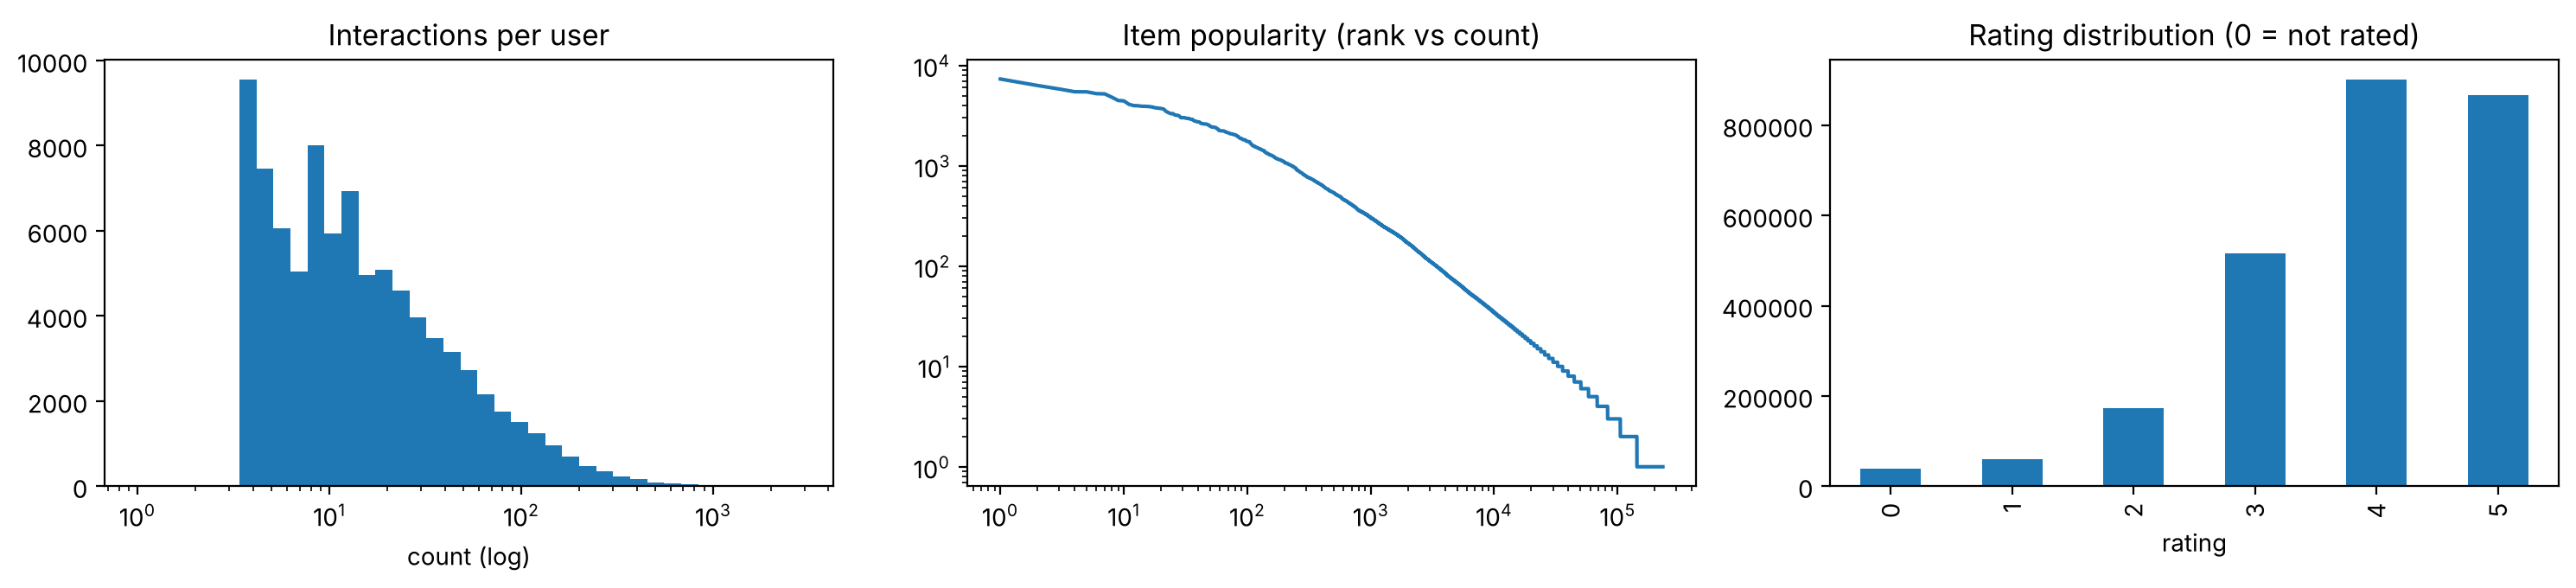

top 1% of items account for 43.6% of interactions


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
per_user = df.groupby("user").size()
ax[0].hist(per_user, bins=np.logspace(0, np.log10(per_user.max()), 40)); ax[0].set_xscale("log")
ax[0].set_title("Interactions per user"); ax[0].set_xlabel("count (log)")
pop = df["item"].value_counts()
ax[1].loglog(np.arange(1, len(pop) + 1), pop.values); ax[1].set_title("Item popularity (rank vs count)")
df.rating.value_counts().sort_index().plot.bar(ax=ax[2]); ax[2].set_title("Rating distribution (0 = not rated)")
plt.tight_layout(); plt.show()
print(f"top 1% of items account for {pop.iloc[:len(pop)//100].sum() / len(df):.1%} of interactions")

invalid timestamps: 468 (0.02%)


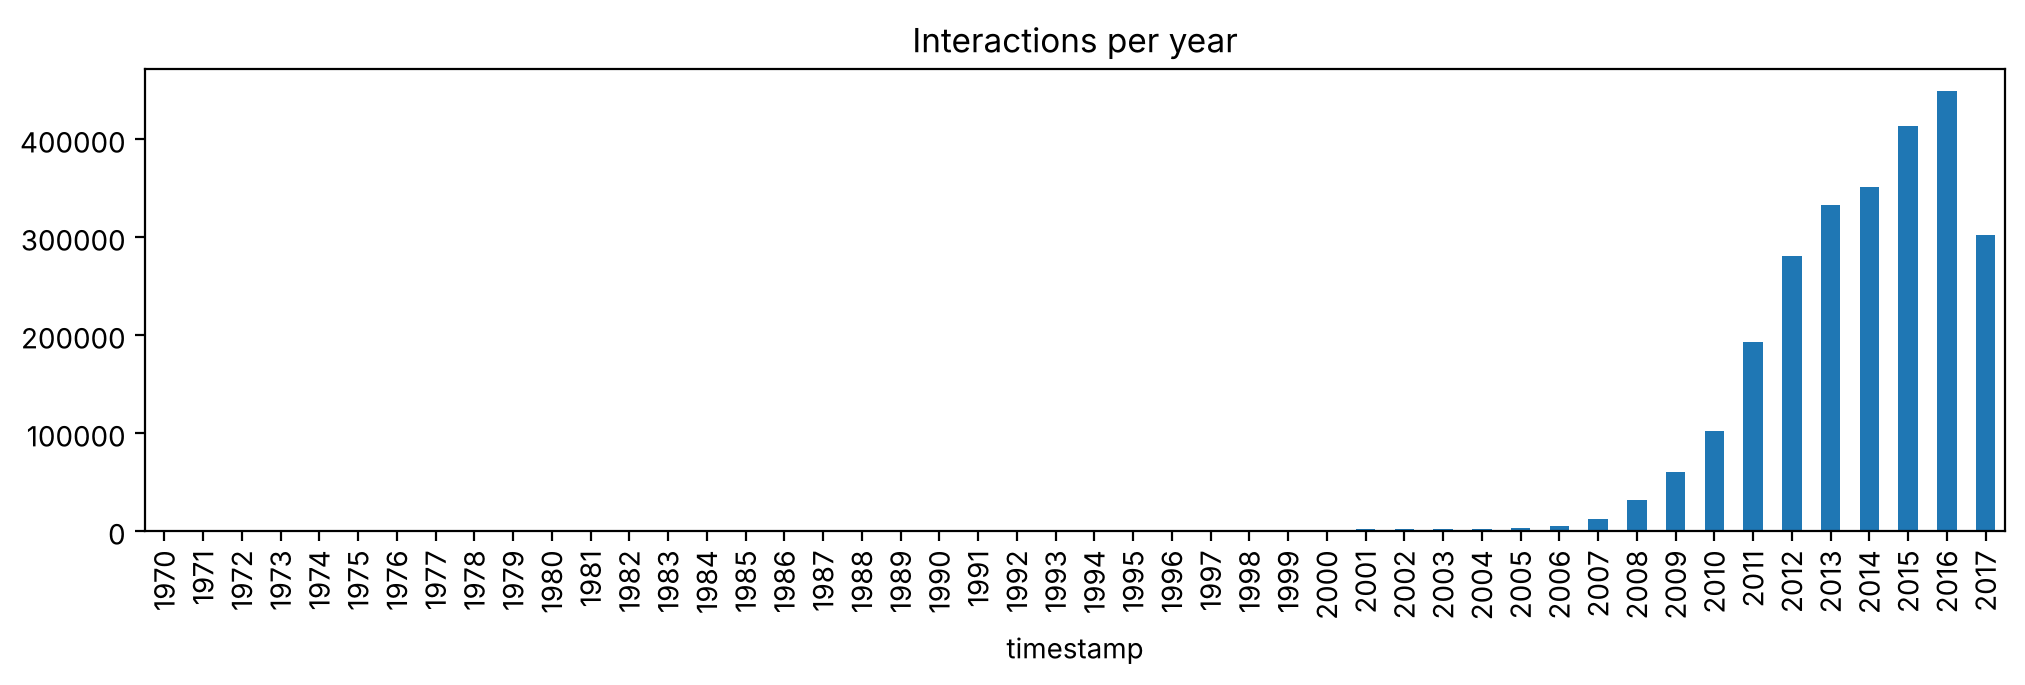

In [7]:
# timestamps: a few values are clearly invalid (negative or far future); report them rather than silently dropping
ts = pd.to_datetime(df.timestamp.clip(0, 2e9), unit="s")
bad = (df.timestamp < 0) | (df.timestamp > 2e9)
print(f"invalid timestamps: {bad.sum():,} ({bad.mean():.2%})")
ts[~bad].dt.year.value_counts().sort_index().plot.bar(figsize=(12, 3), title="Interactions per year")
plt.show()

TODO (Chase): ideas worth showing
* how often a user's next book was read by someone right after the same previous book (shows why sequence models help)
* sparsity of the user-item matrix, cold-start share of validation/test items
* gaps between consecutive interactions
* any preprocessing decisions and why (we keep all users and items; invalid timestamps only affect ordering)

## 3. Modeling (Woosik)

Every model below implements `fit(history_df)` and `score(users, items)`. Baselines first, then models from class.

| Model | Idea | Uses order? |
|---|---|---|
| Popularity | score = how often the item appears in training | no |
| Markov transition | how often other users went from the user's last book to this one, backed off to popularity | yes (last item only) |
| BPR | matrix factorization trained to rank a user's items above other items (Rendle et al. 2009) | no |
| Combined (learning to rank) | gradient boosting over BPR score + transitions + popularity + item timing | yes |

In [8]:
class Popularity:
    def fit(self, hist):
        self.pop = hist["item"].value_counts()
        return self
    def score(self, users, items):
        return np.log1p(self.pop.reindex(items).fillna(0).values)

class MarkovTransition:
    """P(next = i | last = j) estimated from consecutive pairs in all users' histories, with popularity back-off."""
    def __init__(self, alpha=1e-3):
        self.alpha = alpha
    def fit(self, hist):
        h = hist.sort_values(["user", "timestamp"], kind="stable")
        u, i = h.user.values, h["item"].values
        same = u[1:] == u[:-1]
        self.trans = Counter(zip(i[:-1][same], i[1:][same]))
        self.out = Counter(i[:-1][same])
        self.last = h.groupby("user")["item"].last()
        self.pop = Popularity().fit(hist)
        return self
    def score(self, users, items):
        last = self.last.reindex(users).values
        t = np.array([self.trans.get((a, b), 0) / (self.out.get(a, 0) + 1) for a, b in zip(last, items)])
        return t + self.alpha * self.pop.score(users, items)

In [9]:
from implicit import bpr as implicit_bpr

class BPR:
    def __init__(self, factors=64, iterations=100, lr=0.05, reg=0.01):
        self.kw = dict(factors=factors, iterations=iterations, learning_rate=lr, regularization=reg, random_state=SEED)
    def fit(self, hist):
        self.U = pd.Index(hist.user.unique()); self.I = pd.Index(hist["item"].unique())
        X = sp.csr_matrix((np.ones(len(hist)), (self.U.get_indexer(hist.user), self.I.get_indexer(hist["item"]))),
                          shape=(len(self.U), len(self.I)))
        X.data[:] = 1
        m = implicit_bpr.BayesianPersonalizedRanking(**self.kw); m.fit(X, show_progress=False)
        tonp = lambda a: a.to_numpy() if hasattr(a, "to_numpy") else a
        self.uf, self.itf = tonp(m.user_factors), tonp(m.item_factors)
        return self
    def score(self, users, items):
        u, i = self.U.get_indexer(users), self.I.get_indexer(items)
        ok = (u >= 0) & (i >= 0)
        s = np.full(len(u), -1e9)
        s[ok] = (self.uf[u[ok]] * self.itf[i[ok]]).sum(1)
        return s

In [10]:
hist_test = pd.concat([train_df, valid_df])
for name, model in [("Popularity", Popularity()), ("Markov transition", MarkovTransition()), ("BPR (64 factors)", BPR())]:
    t = time.time()
    record(name, model.fit(train_df), hist_test)
    print(f"   {time.time() - t:.0f}s")

Popularity {'pair_acc': np.float64(0.525), 'HR@10': np.float64(0.1416), 'NDCG@10': np.float64(0.0675), 'MRR': np.float64(0.0681)}
   2s


Markov transition {'pair_acc': np.float64(0.5771), 'HR@10': np.float64(0.2737), 'NDCG@10': np.float64(0.1971), 'MRR': np.float64(0.1918)}
   18s


BPR (64 factors) {'pair_acc': np.float64(0.8545), 'HR@10': np.float64(0.6344), 'NDCG@10': np.float64(0.4003), 'MRR': np.float64(0.3439)}
   111s


### Combined model (learning to rank)

**Idea:** BPR knows *who the user is* (long-term taste) but ignores order. The Markov model knows *what came right before* but ignores the user. FPMC (Rendle et al. 2010) combines both inside one factorization. We combine them more flexibly: a gradient boosted classifier learns how much to trust each signal.

**Features for a (user, candidate book) pair**
* BPR score (personal taste)
* transition counts from the user's last 3 books to the candidate, a skip-one transition, and the reverse direction
* overall popularity and popularity in the final year of data
* when the candidate was first, typically and last read by others, relative to the user's last interaction (is the book "current" for this user?)
* user profile: history length and how mainstream their books are

**Training without leakage:** the classifier is trained one step back in time. Base models are fit on each user's history minus their last training item, and that item (vs. 3 popularity-weighted negatives) is the training label. Then the base models are refit on the full history for scoring.

**Trade-offs:** much stronger than any single model, but more moving parts (two BPR fits per run, about 2 minutes each) and less interpretable than one formula.

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier

def _pair_lookup(counter_series, a, b):
    """Vectorized lookup of counts for (a, b) pairs from a Series indexed by a MultiIndex."""
    idx = pd.MultiIndex.from_arrays([a, b])
    return counter_series.reindex(idx).fillna(0).values

class SequenceStats:
    """Order and time statistics used as features: transitions, item timing, user profile."""
    def fit(self, hist):
        h = hist.sort_values(["user", "timestamp"], kind="stable")
        u, i = h.user.values, h["item"].values
        same = u[1:] == u[:-1]
        self.trans = pd.Series(1, index=pd.MultiIndex.from_arrays([i[:-1][same], i[1:][same]])).groupby(level=[0, 1]).sum()
        same2 = u[2:] == u[:-2]
        self.trans2 = pd.Series(1, index=pd.MultiIndex.from_arrays([i[:-2][same2], i[2:][same2]])).groupby(level=[0, 1]).sum()
        g = h.groupby("user")
        self.last1 = g["item"].last()
        self.last2 = g["item"].apply(lambda x: x.values[-2] if len(x) > 1 else None)
        self.last3 = g["item"].apply(lambda x: x.values[-3] if len(x) > 2 else None)
        self.u_last_t = g.timestamp.max(); self.u_n = g.size()
        pop = h["item"].value_counts(); self.pop = pop
        self.u_meanpop = np.log1p(pop.reindex(h["item"]).values)
        self.u_meanpop = pd.Series(self.u_meanpop).groupby(u).mean()
        it = h.groupby("item").timestamp
        self.i_first, self.i_med, self.i_last = it.min(), it.median(), it.max()
        tmax = h.timestamp.quantile(0.999)
        recent = h[h.timestamp > tmax - 365 * 86400]["item"].value_counts()   # popularity in the final year
        self.recent = recent
        return self
    def features(self, users, items):
        users = np.asarray(users); items = np.asarray(items)
        lt = self.u_last_t.reindex(users).values
        rel = lambda s: (lambda d: np.sign(d) * np.log1p(np.abs(d)))(s.reindex(items).values - lt)
        p = self.pop.reindex(items).fillna(0).values
        return np.c_[
            np.log1p(p),
            np.log1p(self.recent.reindex(items).fillna(0).values),
            np.log1p(_pair_lookup(self.trans, self.last1.reindex(users).values, items)),
            np.log1p(_pair_lookup(self.trans, self.last2.reindex(users).values, items)),
            np.log1p(_pair_lookup(self.trans, self.last3.reindex(users).values, items)),
            np.log1p(_pair_lookup(self.trans2, self.last2.reindex(users).values, items)),
            np.log1p(_pair_lookup(self.trans, items, self.last1.reindex(users).values)),   # reverse direction
            rel(self.i_first), rel(self.i_med), rel(self.i_last),
            np.log1p(self.u_n.reindex(users).values), self.u_meanpop.reindex(users).values,
        ]

class Combined:
    """Learning-to-rank on top of the base models: a gradient boosted classifier that separates each user's
    next item from popularity-weighted negatives, using BPR scores plus sequence and time features.
    To avoid leakage, the classifier is trained one step earlier in time: base models are fit on the history
    without each user's last item, and that last item is the training target."""
    def __init__(self, n_neg=3, bpr_kw=None):
        self.n_neg = n_neg; self.bpr_kw = bpr_kw or {}
    def _X(self, bpr_m, stats, users, items):
        return np.c_[bpr_m.score(users, items), stats.features(users, items)]
    def fit(self, hist):
        h = hist.sort_values(["user", "timestamp"], kind="stable")
        last = h.groupby("user").tail(1); prev = h.drop(last.index)
        last = last[last.user.isin(prev.user.unique())]
        b0, s0 = BPR(**self.bpr_kw).fit(prev), SequenceStats().fit(prev)
        negs = sample_negatives(last, prev, self.n_neg, seed=7)
        U = np.r_[last.user.values, np.repeat(last.user.values, self.n_neg)]
        I = np.r_[last["item"].values, negs.ravel()]
        y = np.r_[np.ones(len(last)), np.zeros(negs.size)]
        X = self._X(b0, s0, U, I)
        X[:, 0] = np.where(X[:, 0] < -1e8, np.nan, X[:, 0])
        self.clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, max_leaf_nodes=63,
                                                  min_samples_leaf=100, random_state=SEED).fit(X, y)
        self.bpr, self.stats = BPR(**self.bpr_kw).fit(h), SequenceStats().fit(h)   # refit on full history for scoring
        return self
    def score(self, users, items):
        X = self._X(self.bpr, self.stats, users, items)
        X[:, 0] = np.where(X[:, 0] < -1e8, np.nan, X[:, 0])
        return self.clf.predict_proba(X)[:, 1]

In [12]:
t = time.time()
combined = Combined().fit(train_df)
record("Combined (learning to rank)", combined, hist_test)
print(f"   {time.time() - t:.0f}s")

Combined (learning to rank) {'pair_acc': np.float64(0.9204), 'HR@10': np.float64(0.7546), 'NDCG@10': np.float64(0.556), 'MRR': np.float64(0.5062)}
   383s


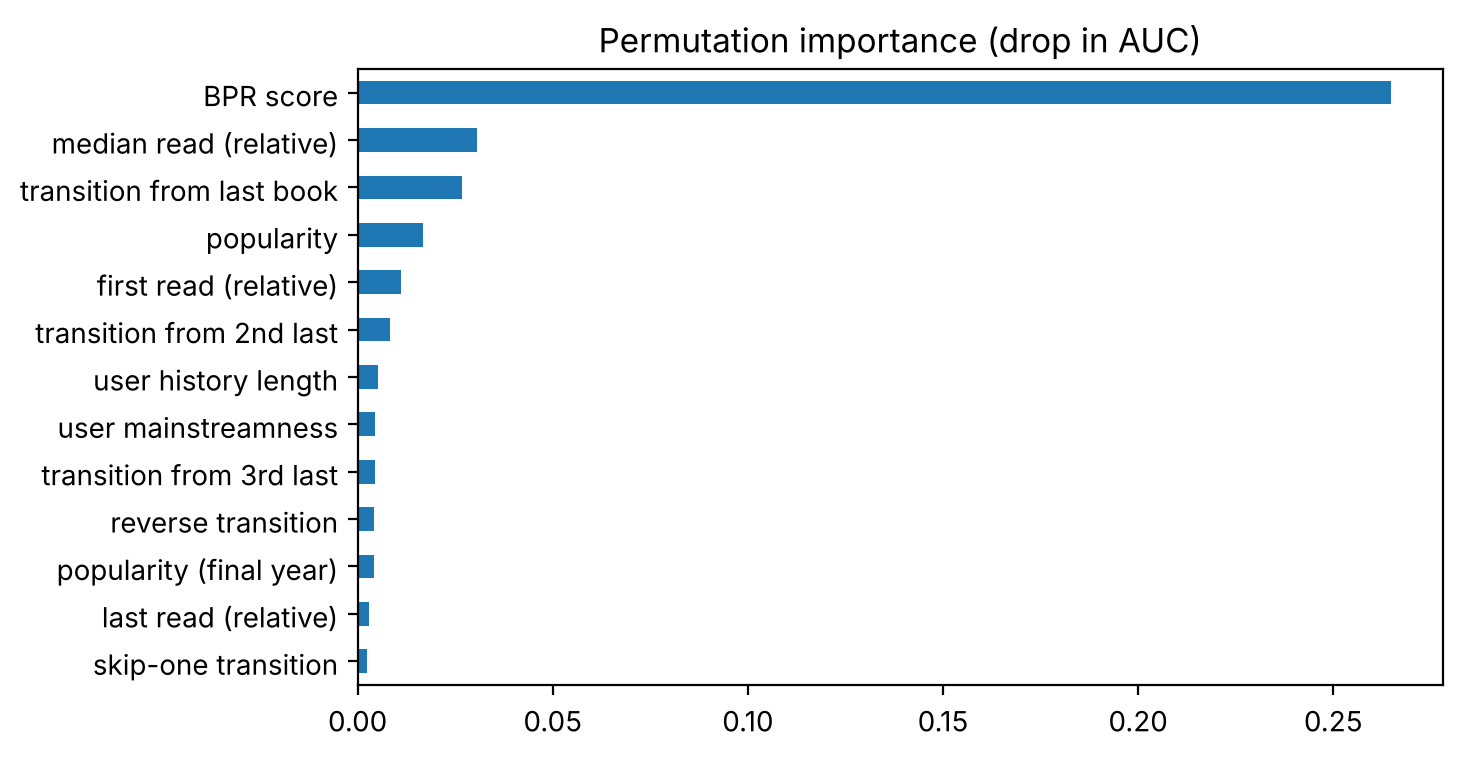

In [13]:
# which signals does the combined model rely on? permutation importance on validation pairs
from sklearn.inspection import permutation_importance
names = ["BPR score", "popularity", "popularity (final year)", "transition from last book", "transition from 2nd last",
         "transition from 3rd last", "skip-one transition", "reverse transition", "first read (relative)",
         "median read (relative)", "last read (relative)", "user history length", "user mainstreamness"]
m = combined.fit(train_df)          # back to the validation-time model
sub = valid_df.sample(10000, random_state=SEED)
U = np.r_[sub.user.values, sub.user.values]
I = np.r_[sub["item"].values, PAIR_NEG["valid"][sub.index.values]]
X = m._X(m.bpr, m.stats, U, I); X[:, 0] = np.where(X[:, 0] < -1e8, np.nan, X[:, 0])
y = np.r_[np.ones(len(sub)), np.zeros(len(sub))]
imp = permutation_importance(m.clf, X, y, scoring="roc_auc", n_repeats=3, random_state=SEED)
pd.Series(imp.importances_mean, index=names).sort_values().plot.barh(figsize=(7, 4), title="Permutation importance (drop in AUC)")
plt.show()

TODO (Woosik): talking points for the video
* why order matters here (transition features are near the top) and why BPR alone plateaus
* why the item timing features help: the next book is usually one other people were reading around the same time
* possible extensions: FPMC or SASRec as a single end-to-end model, tuning BPR factors on validation

## 4. Evaluation (Aung)

*Rubric section 4: justify the metrics, compare against baselines, support with tables and plots.*

,valid_pair_acc,valid_HR@10,valid_NDCG@10,valid_MRR,test_pair_acc,test_HR@10,test_NDCG@10,test_MRR
model,,,,,,,,
Popularity,0.5313,0.1508,0.0718,0.0710,0.5250,0.1416,0.0675,0.0681
Markov transition,0.5840,0.2808,0.2051,0.2003,0.5771,0.2737,0.1971,0.1918
BPR (64 factors),0.8555,0.6378,0.4080,0.3526,0.8545,0.6344,0.4003,0.3439
Combined (learning to rank),0.9186,0.7476,0.5528,0.5044,0.9204,0.7546,0.5560,0.5062


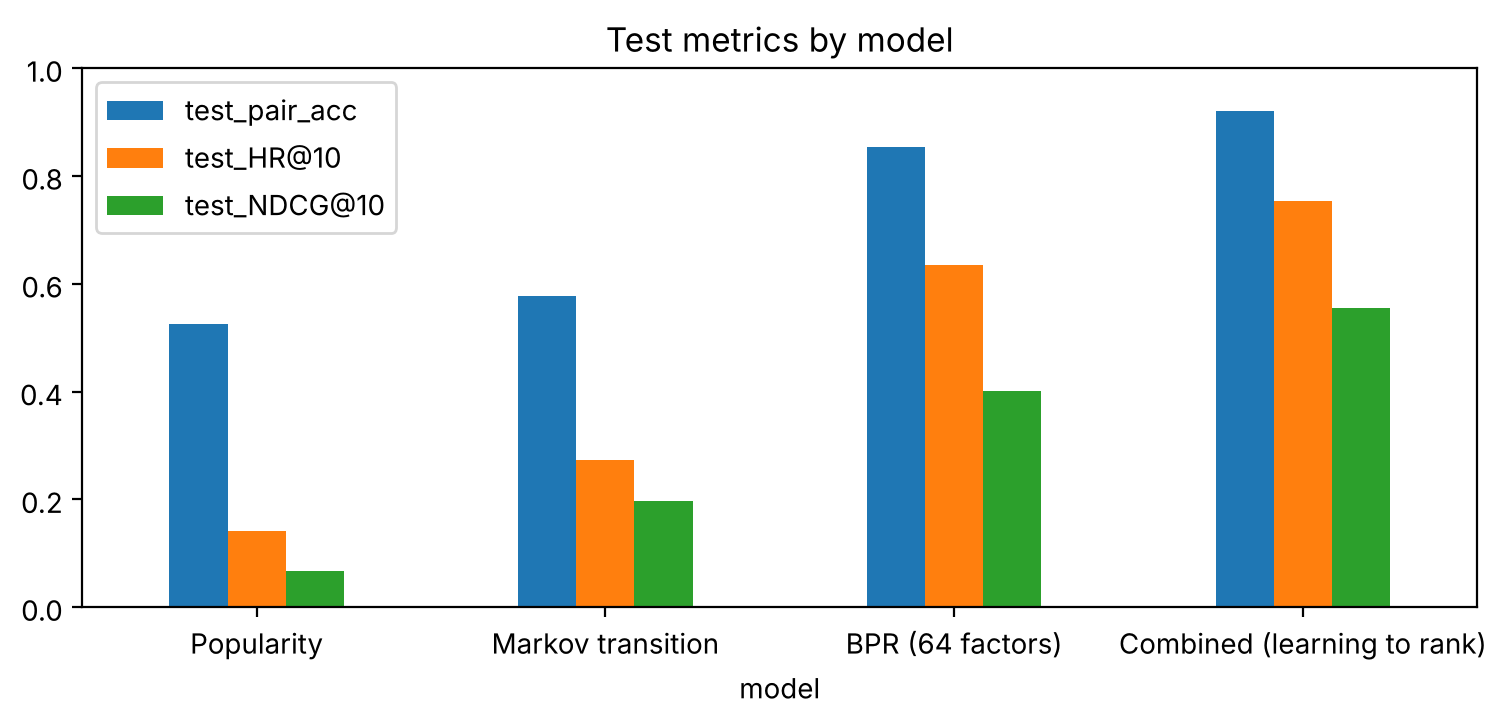

In [14]:
res = pd.DataFrame(RESULTS).set_index("model")
display(res.round(4))
res[["test_pair_acc", "test_HR@10", "test_NDCG@10"]].plot.bar(figsize=(9, 3.5), rot=0, title="Test metrics by model")
plt.ylim(0, 1); plt.show()

TODO (Aung): ideas
* why ranking metrics (HR@10, NDCG@10) matter more than accuracy for a recommender, and the caveat that sampled metrics can change model rankings (Krichene and Rendle 2020)
* break results down by user activity (few vs many past books) and by item popularity of the true next book
* validation vs. test gap for each model (is anything overfitting?)
* significance: bootstrap confidence intervals over users

## 5. Related work (Shriya)

*Rubric section 5: how this dataset and task were studied before, and how our results compare. Starting points (verify details before citing):*
* Mengting Wan, Julian McAuley. *Item Recommendation on Monotonic Behavior Chains.* RecSys 2018 (introduces the Goodreads dataset)
* Steffen Rendle et al. *BPR: Bayesian Personalized Ranking from Implicit Feedback.* UAI 2009
* Steffen Rendle, Christoph Freudenthaler, Lars Schmidt-Thieme. *Factorizing Personalized Markov Chains for Next-Basket Recommendation.* WWW 2010
* Ruining He, Julian McAuley. *Fusing Similarity Models with Markov Chains for Sparse Sequential Recommendation.* ICDM 2016
* Wang-Cheng Kang, Julian McAuley. *Self-Attentive Sequential Recommendation (SASRec).* ICDM 2018
* Walid Krichene, Steffen Rendle. *On Sampled Metrics for Item Recommendation.* KDD 2020

TODO